# 実験2 (`ex002`): EPIC におけるチャネル分離度（Purity）と分類精度の関係に関する再現・発展実験

本ノートブックでは，2026年 電子情報通信学会ソサイエティ大会 論文（`N-1-43`）**「EPICにおけるチャネル分離度と分類精度の関係に関する検討」**（室岡・代・神野, 2026）の再現実験および，同論文の考察・今後の課題で提起された交絡要因の定量的検証を行う．

## 実験項目
1. **ImageNet 事前学習済み ResNet-34 の Imagenette ファインチューニングと EPIC Disentanglement 学習（予測完全保存性の確認）**
2. **全512チャネルの Purity 分布と5群（G1〜G5）分類の分析**
3. **群別単独分類精度（論文 表1 対応）および高 Purity 側からの累積追加精度・単一群除去精度の検証（論文 図1 対応）**
4. **交絡要因の定量的切り分け（論文 3節・4節の検証：チャネル数統制・分類層重みノルム・対応クラス分布の偏り）**
5. **Purity 群（G1・G3・G5）別の視覚的プロトタイプ特徴の定性比較**

---

In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import torch

from model import ImagenetteResNet34, ChannelMaskedEPICResNet34
from utils import (
    IMAGENETTE_CLASSES_JA,
    PAPER_TABLE1_REF,
    setup_japanese_matplotlib,
    preload_imagenette_uint8,
    center_crop_uint8,
    finetune_resnet34_on_imagenette,
    extract_feature_maps,
    verify_epic_equivalence_10cls,
    compute_channel_purities,
    train_epic_on_features,
    assign_purity_groups,
    evaluate_single_and_cumulative_groups,
    evaluate_m_proto_sensitivity,
    analyze_confounding_factors,
    find_activation_bbox,
)

setup_japanese_matplotlib()
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"使用デバイス: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

PROJECT_ROOT = Path("..").resolve()
DATASET_DIR = PROJECT_ROOT / "datasets"
IMG_DIR = PROJECT_ROOT / "report" / "img"
IMG_DIR.mkdir(parents=True, exist_ok=True)

# Imagenette (train=9,469枚, val=3,925枚) をメモリ上に高速プリロード
t0 = time.time()
x_train_256, y_train, x_val_256, y_val = preload_imagenette_uint8(DATASET_DIR, resize_shorter=256, num_workers=8)
print(f"読み込み完了 ({time.time() - t0:.2f}秒): train={tuple(x_train_256.shape)}, val={tuple(x_val_256.shape)}")

使用デバイス: cuda (NVIDIA GeForce RTX 4080)
読み込み完了 (13.55秒): train=(9469, 3, 256, 256), val=(3925, 3, 256, 256)


Imagenette (val) 画像読み込み: 100%|##########| 3925/3925 [00:02<00:00, 1646.59it/s]


## 1. ResNet-34 の Imagenette ファインチューニングと EPIC の適用

論文 2節の実験設定に従い，ImageNet-1K 事前学習済み `ResNet-34`（最終層直前 $D = 512$ チャネル）を `Imagenette`（10クラス）でファインチューニングする．その後，バックボーンと線形分類層を凍結した状態で `ChannelMaskedEPICResNet34`（Cayley 直交変換 $U \in \mathbb{R}^{512 \times 512}$ ）を構築し，EPIC の標準設定（20エポック，2エポックごとにプロトタイプ枚数 $m$ を $100 \to 5$ へ動的削減）で特徴チャネルを分離する．

---

特徴マップ形状: z_train=(9469, 512, 7, 7), z_val=(3925, 512, 7, 7)


EPIC Disentanglement 学習: 100%|##########| 20/20 [00:05<00:00,  3.96it/s, m=5, loss=0.3929, purity=0.6133]


,epoch,lr,train_loss,train_acc,val_loss,val_acc
0,1,0.004665,0.1818,0.9479,0.0398,0.9901
1,2,0.003750,0.0256,0.9933,0.0408,0.9878
2,3,0.002500,0.0119,0.9976,0.0340,0.9885
3,4,0.001250,0.0091,0.9983,0.0296,0.9893
4,5,0.000335,0.0053,0.9993,0.0282,0.9908
5,6,0.000000,0.0058,0.9993,0.0278,0.9903


,EPIC適用前_Val_Accuracy,EPIC適用後_Val_Accuracy,予測一致率(%),最大ロジット絶対誤差,直交誤差_||U^T U - I||_F
0,0.9903,0.9903,100.0,0.00001,0.000009


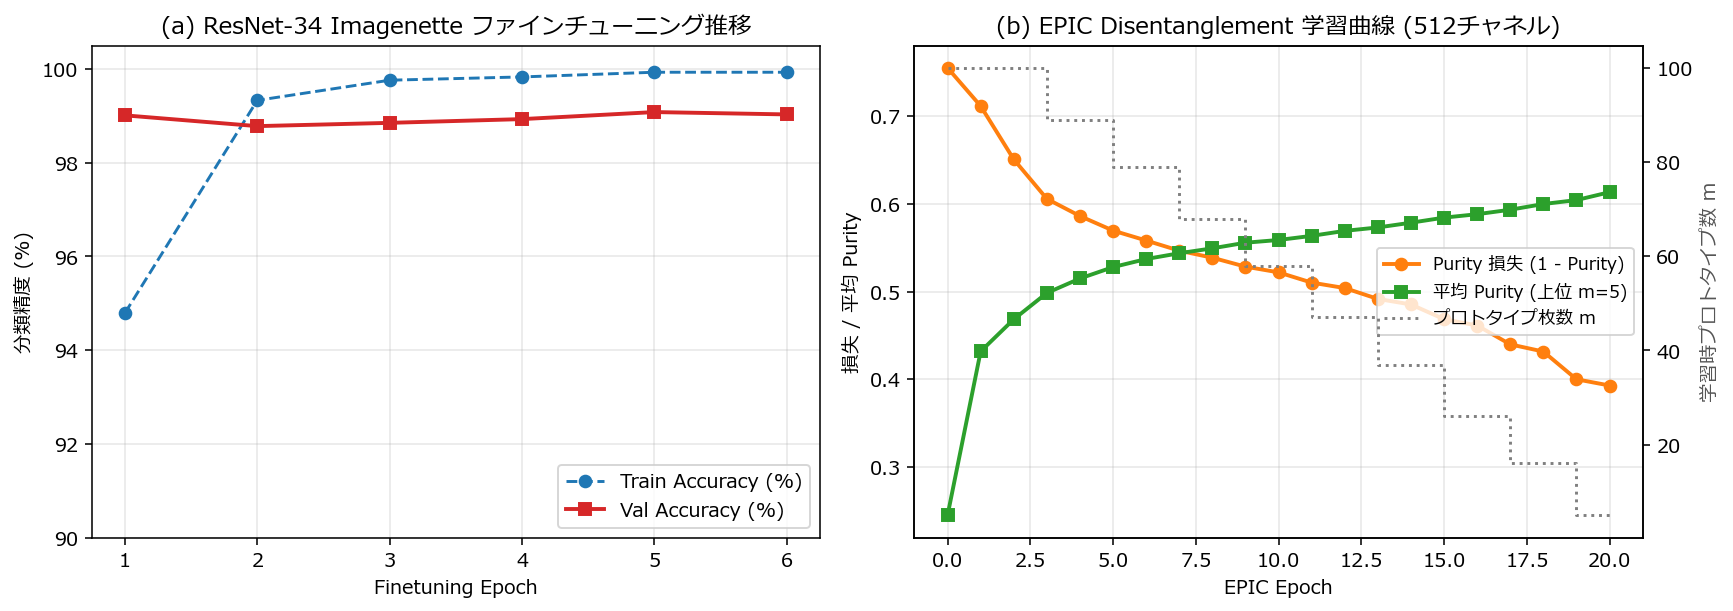

In [2]:
# 1-1. ResNet-34 のファインチューニング (SGD + CosineAnnealing, 6 epochs)
ft_model = ImagenetteResNet34(num_classes=10, pretrained=True)
ft_hist_df = finetune_resnet34_on_imagenette(
    ft_model,
    x_train_256=x_train_256,
    y_train=y_train,
    x_val_256=x_val_256,
    y_val=y_val,
    device=device,
    epochs=6,
    batch_size=64,
    lr=0.005,
    seed=42,
)
display(ft_hist_df)

# 1-2. 凍結した layer4 特徴マップ Z ∈ R^{N×512×7×7} を一括抽出
z_train = extract_feature_maps(ft_model, x_train_256, device=device, desc="訓練データ特徴抽出")
z_val = extract_feature_maps(ft_model, x_val_256, device=device, desc="検証データ特徴抽出")
print(f"特徴マップ形状: z_train={tuple(z_train.shape)}, z_val={tuple(z_val.shape)}")

# 1-3. EPIC Disentanglement Module の学習 (20 epochs)
epic_model = ChannelMaskedEPICResNet34(ft_model, matrix_type="orthogonal")
pur_before_m5, _ = compute_channel_purities(z_train, epic_model.disentangle.get_matrix(), m_proto=5, device=device)

epic_hist_df = train_epic_on_features(
    epic_model,
    z_train=z_train,
    device=device,
    epochs=20,
    recalc_every=2,
    m_start=100,
    m_end=5,
    batch_size=512,
    lr=0.001,
    m_eval_purity=5,
    seed=42,
)

# 1-4. EPIC 適用前後の分類精度・予測一致率の検証
equiv_stats = verify_epic_equivalence_10cls(ft_model, epic_model, x_val_256, y_val, device=device)
equiv_df = pd.DataFrame([equiv_stats])
display(equiv_df)

# 図1: ファインチューニング推移と EPIC 学習推移の保存
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))

ax1 = axes[0]
ax1.plot(ft_hist_df["epoch"], ft_hist_df["train_acc"] * 100, "o--", color="#1f77b4", label="Train Accuracy (%)")
ax1.plot(ft_hist_df["epoch"], ft_hist_df["val_acc"] * 100, "s-", color="#d62728", linewidth=2, label="Val Accuracy (%)")
ax1.set_xlabel("Finetuning Epoch")
ax1.set_ylabel("分類精度 (%)")
ax1.set_title("(a) ResNet-34 Imagenette ファインチューニング推移")
ax1.set_ylim(90, 100.5)
ax1.grid(True, alpha=0.3)
ax1.legend(loc="lower right")

ax2 = axes[1]
ax2.plot(epic_hist_df["epoch"], epic_hist_df["loss"], "o-", color="#ff7f0e", linewidth=2, label="Purity 損失 (1 - Purity)")
ax2.plot(epic_hist_df["epoch"], epic_hist_df["mean_purity"], "s-", color="#2ca02c", linewidth=2, label="平均 Purity (上位 m=5)")
ax2_sub = ax2.twinx()
ax2_sub.step(epic_hist_df["epoch"], epic_hist_df["m_prototypes"], where="post", linestyle=":", color="#7f7f7f", label="プロトタイプ枚数 m")
ax2_sub.set_ylabel("学習時プロトタイプ数 m", color="#555555")
ax2.set_xlabel("EPIC Epoch")
ax2.set_ylabel("損失 / 平均 Purity")
ax2.set_title("(b) EPIC Disentanglement 学習曲線 (512チャネル)")
ax2.grid(True, alpha=0.3)
lines1, labels1 = ax2.get_legend_handles_labels()
lines2, labels2 = ax2_sub.get_legend_handles_labels()
ax2.legend(lines1 + lines2, labels1 + labels2, loc="center right", fontsize=9)

plt.tight_layout()
plt.savefig(IMG_DIR / "ex002_finetune_and_epic.png", dpi=160, bbox_inches="tight")
plt.show()

## 2. 全512チャネルの Purity 分布と5群（G1〜G5）分類

論文 表1 の定義に従い，EPIC 適用後の各チャネルの Purity に基づいて全512チャネルを以下の5群に分類する：
- **G1**： $\mathrm{Purity} \geq 0.60$ （最高分離度群）
- **G2**： $0.55 \leq \mathrm{Purity} \lt 0.60$
- **G3**： $0.50 \leq \mathrm{Purity} \lt 0.55$
- **G4**： $0.45 \leq \mathrm{Purity} \lt 0.50$
- **G5**： $\mathrm{Purity} \lt 0.45$ （低分離度群）

ここでは EPIC 学習終了時の標準評価枚数 $m_{\mathrm{eval}} = 5$ に加え，より広いプロトタイプ集合で平均純度を評価した $m_{\mathrm{eval}} = 12$ ，および論文 表1 の参照チャネル数分布を比較する．

---

,条件,平均Purity,標準偏差,最小値,中央値,最大値
0,"EPIC適用前 (U = I, m=5)",0.2450,0.0496,0.1455,0.2381,0.4596
1,EPIC適用後 (主設定: m_eval=5),0.6133,0.0934,0.3896,0.6068,0.8737
2,EPIC適用後 (広域評価: m_eval=12),0.5887,0.0878,0.3905,0.5782,0.8302


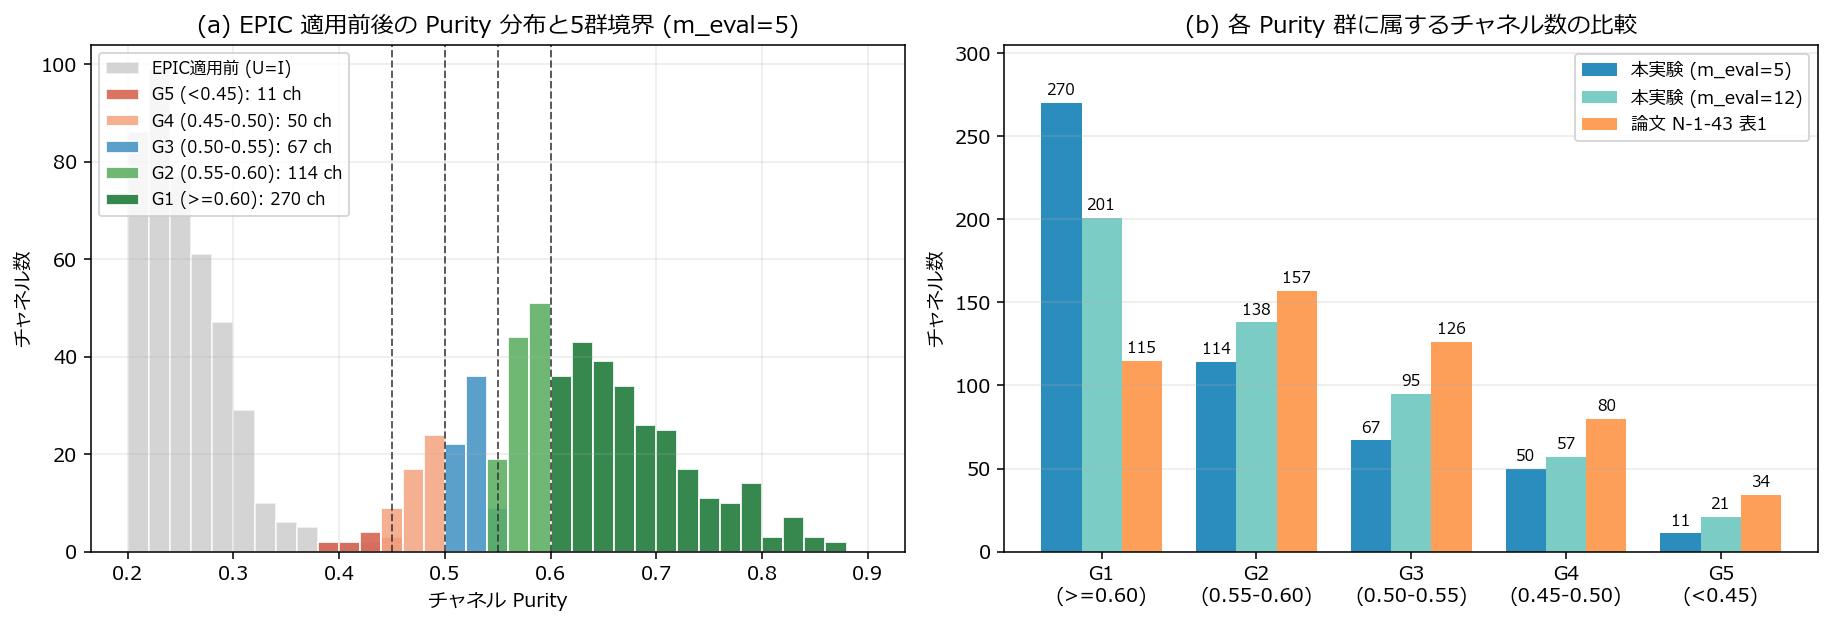

In [3]:
U_trained = epic_model.disentangle.get_matrix()
pur_after_m5, top_idx_m5 = compute_channel_purities(z_train, U_trained, m_proto=5, device=device)
pur_after_m12, _ = compute_channel_purities(z_train, U_trained, m_proto=12, device=device)

groups_m5 = assign_purity_groups(pur_after_m5)
groups_m12 = assign_purity_groups(pur_after_m12)

purity_summary_df = pd.DataFrame(
    [
        {
            "条件": "EPIC適用前 (U = I, m=5)",
            "平均Purity": round(float(pur_before_m5.mean()), 4),
            "標準偏差": round(float(pur_before_m5.std()), 4),
            "最小値": round(float(pur_before_m5.min()), 4),
            "中央値": round(float(pur_before_m5.median()), 4),
            "最大値": round(float(pur_before_m5.max()), 4),
        },
        {
            "条件": "EPIC適用後 (主設定: m_eval=5)",
            "平均Purity": round(float(pur_after_m5.mean()), 4),
            "標準偏差": round(float(pur_after_m5.std()), 4),
            "最小値": round(float(pur_after_m5.min()), 4),
            "中央値": round(float(pur_after_m5.median()), 4),
            "最大値": round(float(pur_after_m5.max()), 4),
        },
        {
            "条件": "EPIC適用後 (広域評価: m_eval=12)",
            "平均Purity": round(float(pur_after_m12.mean()), 4),
            "標準偏差": round(float(pur_after_m12.std()), 4),
            "最小値": round(float(pur_after_m12.min()), 4),
            "中央値": round(float(pur_after_m12.median()), 4),
            "最大値": round(float(pur_after_m12.max()), 4),
        },
    ]
)
display(purity_summary_df)

# 図2: Purity ヒストグラム（G1〜G5 色分け）と群別チャネル数の比較
group_colors = {
    "G1": "#1b7837",
    "G2": "#5aae61",
    "G3": "#4393c3",
    "G4": "#f4a582",
    "G5": "#d6604d",
}

fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.6))

ax = axes[0]
bins = np.linspace(0.20, 0.90, 36)
ax.hist(pur_before_m5.numpy(), bins=bins, color="#bdbdbd", alpha=0.65, edgecolor="white", label="EPIC適用前 (U=I)")

p_np = pur_after_m5.numpy()
for g_name, rng_label in [("G5", "G5 (<0.45)"), ("G4", "G4 (0.45-0.50)"), ("G3", "G3 (0.50-0.55)"), ("G2", "G2 (0.55-0.60)"), ("G1", "G1 (>=0.60)")]:
    sub = p_np[groups_m5[g_name].numpy()]
    ax.hist(sub, bins=bins, color=group_colors[g_name], alpha=0.88, edgecolor="white", label=f"{rng_label}: {len(sub)} ch")

for th in [0.45, 0.50, 0.55, 0.60]:
    ax.axvline(th, color="#333333", linestyle="--", linewidth=1.0, alpha=0.8)

ax.set_xlabel("チャネル Purity")
ax.set_ylabel("チャネル数")
ax.set_title("(a) EPIC 適用前後の Purity 分布と5群境界 (m_eval=5)")
ax.legend(fontsize=8.5, loc="upper left")
ax.grid(True, alpha=0.25)

axb = axes[1]
g_names = ["G1", "G2", "G3", "G4", "G5"]
x_pos = np.arange(len(g_names))
w = 0.26
cnt_m5 = [int(groups_m5[g].sum().item()) for g in g_names]
cnt_m12 = [int(groups_m12[g].sum().item()) for g in g_names]
cnt_ref = [PAPER_TABLE1_REF[g][1] for g in g_names]

b1 = axb.bar(x_pos - w, cnt_m5, width=w, color="#2b8cbe", label="本実験 (m_eval=5)")
b2 = axb.bar(x_pos, cnt_m12, width=w, color="#7bccc4", label="本実験 (m_eval=12)")
b3 = axb.bar(x_pos + w, cnt_ref, width=w, color="#fd8d3c", alpha=0.85, label="論文 N-1-43 表1")

for bars in [b1, b2, b3]:
    for bar in bars:
        h = int(bar.get_height())
        axb.text(bar.get_x() + bar.get_width() / 2, h + 3, str(h), ha="center", va="bottom", fontsize=8)

axb.set_xticks(x_pos)
axb.set_xticklabels(["G1\n(>=0.60)", "G2\n(0.55-0.60)", "G3\n(0.50-0.55)", "G4\n(0.45-0.50)", "G5\n(<0.45)"])
axb.set_ylabel("チャネル数")
axb.set_ylim(0, max(cnt_m5) + 35)
axb.set_title("(b) 各 Purity 群に属するチャネル数の比較")
axb.legend(fontsize=9)
axb.grid(True, axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(IMG_DIR / "ex002_purity_groups.png", dpi=160, bbox_inches="tight")
plt.show()

## 3. 群別単独分類精度（論文 表1）と累積追加・除去評価（論文 図1）

論文 2節の手順に従い，分類推論時に対象群以外のチャネル出力を $0$ にマスクして検証データ（3,925 枚）に対する分類精度を評価する．
1. **群別単独評価（論文 表1 対応）**：`G1`〜`G5` の各群のみを用いた際の分類精度を評価する．
2. **高 Purity 側からの累積追加評価（論文 図1 対応）**：`keep_G1` $\to$ `keep_G1_G2` $\to$ `keep_G1_G2_G3` $\to$ `keep_G1_G2_G3_G4` $\to$ `keep_all` の精度推移を評価する．
3. **低 Purity 側からの累積追加および単一群除去（Leave-One-Group-Out）**：`G5` の情報が `G1`〜`G4` に対して冗長であるかを直接検証する．
4. **プロトタイプ評価枚数の感度分析**：評価プロトタイプ枚数 $m_{\mathrm{eval}} \in \lbrace 5, 10, 12, 15, 25 \rbrace$ を変えた際の挙動の頑健性を確認する．

---

=== [1] 群別単独精度の比較（論文 表1 対応, 主設定 m_eval=5）===
=== [2] 高Purity側からの累積追加精度（論文 図1 対応, 主設定 m_eval=5）===
=== [3] 低Purity側からの累積追加 ＆ 単一群除去（冗長性の直接検証, m_eval=5）===
=== [4] Purity 評価プロトタイプ数 m_eval に対する感度分析 ===


,群,Purity範囲,チャネル数(本実験),Accuracy(本実験),チャネル数(論文表1),Accuracy(論文表1)
0,G1,>= 0.60,270,0.8749,115,0.7778
1,G2,0.55-0.60,114,0.8994,157,0.8713
2,G3,0.50-0.55,67,0.5750,126,0.8471
3,G4,0.45-0.50,50,0.6749,80,0.7763
4,G5,< 0.45,11,0.1722,34,0.6189
5,Baseline,All (512),512,0.9903,512,0.8736


,設定,使用群,累積チャネル数,Accuracy,Baseline比差分
0,keep_G1,G1,270,0.8749,-0.1154
1,keep_G1_G2,G1+G2,384,0.9781,-0.0122
2,keep_G1_G2_G3,G1+G2+G3,451,0.9893,-0.0010
3,keep_G1_G2_G3_G4,G1+G2+G3+G4,501,0.9898,-0.0005
4,keep_all,G1+G2+G3+G4+G5,512,0.9903,0.0000


,評価種別,設定,使用チャネル数,Accuracy,Baseline比差分
0,低Purity側から累積追加,keep_G5,11,0.1722,-0.8181
1,低Purity側から累積追加,keep_G5_G4,61,0.7508,-0.2395
2,低Purity側から累積追加,keep_G5_G4_G3,128,0.9236,-0.0668
3,低Purity側から累積追加,keep_G5_G4_G3_G2,242,0.9755,-0.0148
4,低Purity側から累積追加,keep_all,512,0.9903,0.0000
5,単一群のみ除去 (Leave-One-Out),drop_G1,242,0.9755,-0.0148
6,単一群のみ除去 (Leave-One-Out),drop_G2,398,0.9809,-0.0094
7,単一群のみ除去 (Leave-One-Out),drop_G3,445,0.9880,-0.0023
8,単一群のみ除去 (Leave-One-Out),drop_G4,462,0.9898,-0.0005
9,単一群のみ除去 (Leave-One-Out),drop_G5,501,0.9898,-0.0005


,m_eval,平均Purity,G1_ch,G2_ch,G3_ch,G4_ch,G5_ch,G1単独Acc,G2単独Acc,G3単独Acc,G4単独Acc,G5単独Acc,G1..G4累積Acc,Baseline_Acc
0,5,0.6133,270,114,67,50,11,0.8749,0.8994,0.5750,0.6749,0.1722,0.9898,0.9903
1,10,0.5931,217,128,94,50,23,0.8298,0.5888,0.8647,0.4662,0.3587,0.9903,0.9903
2,12,0.5887,201,138,95,57,21,0.8318,0.6989,0.7845,0.6288,0.3014,0.9903,0.9903
3,15,0.5833,186,131,106,68,21,0.9251,0.6059,0.8759,0.5615,0.3101,0.9906,0.9903
4,25,0.5576,143,103,128,80,58,0.8247,0.5610,0.6102,0.6718,0.6224,0.9880,0.9903


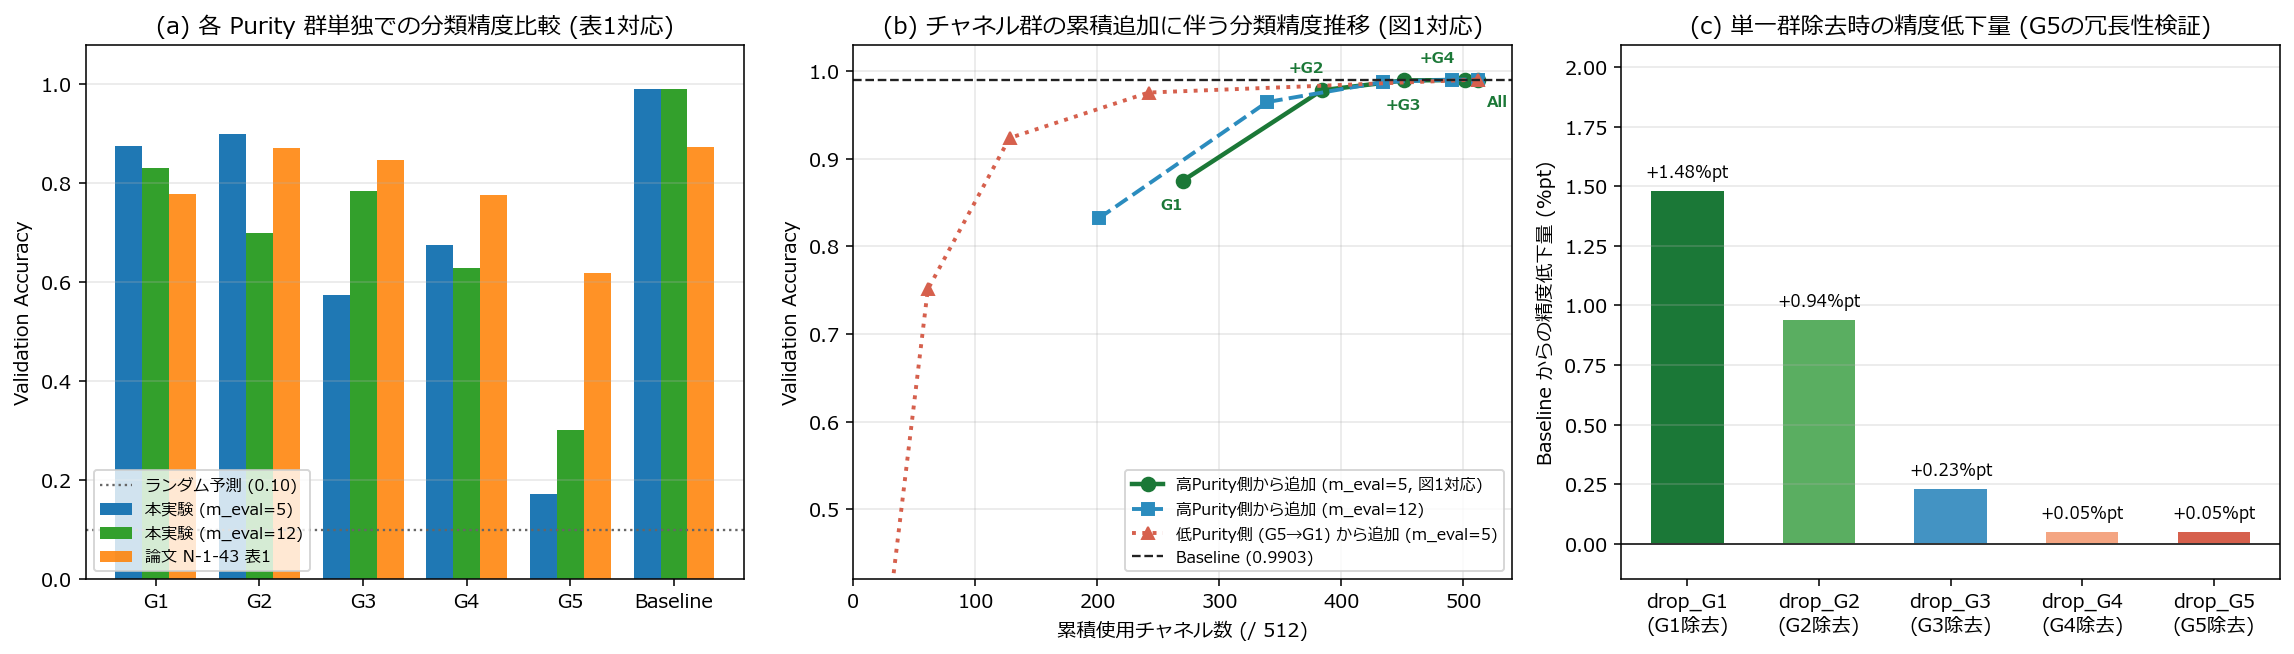

In [4]:
# 主設定 (m_eval=5) および広域評価 (m_eval=12) での評価
single_m5_df, cum_m5_df, extra_m5_df = evaluate_single_and_cumulative_groups(
    epic_model, z_val, y_val, groups_m5, device=device
)
single_m12_df, cum_m12_df, extra_m12_df = evaluate_single_and_cumulative_groups(
    epic_model, z_val, y_val, groups_m12, device=device
)

print("=== [1] 群別単独精度の比較（論文 表1 対応, 主設定 m_eval=5）===")
display(single_m5_df)

print("=== [2] 高Purity側からの累積追加精度（論文 図1 対応, 主設定 m_eval=5）===")
display(cum_m5_df)

print("=== [3] 低Purity側からの累積追加 ＆ 単一群除去（冗長性の直接検証, m_eval=5）===")
display(extra_m5_df)

# m_eval 感度分析テーブル
sens_df = evaluate_m_proto_sensitivity(
    epic_model, z_train, z_val, y_val, m_list=[5, 10, 12, 15, 25], device=device
)
print("=== [4] Purity 評価プロトタイプ数 m_eval に対する感度分析 ===")
display(sens_df)

# 図3: (a) 群別単独精度, (b) 累積追加曲線 (図1対応), (c) 単一群除去時の精度低下量
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))

# Panel (a): 単独精度棒グラフ
ax0 = axes[0]
labels_g = ["G1", "G2", "G3", "G4", "G5", "Baseline"]
x_g = np.arange(len(labels_g))
w = 0.26
acc_m5 = single_m5_df["Accuracy(本実験)"].values
acc_m12 = single_m12_df["Accuracy(本実験)"].values
acc_ref = single_m5_df["Accuracy(論文表1)"].values

ax0.bar(x_g - w, acc_m5, width=w, color="#1f78b4", label="本実験 (m_eval=5)")
ax0.bar(x_g, acc_m12, width=w, color="#33a02c", label="本実験 (m_eval=12)")
ax0.bar(x_g + w, acc_ref, width=w, color="#ff7f00", alpha=0.85, label="論文 N-1-43 表1")
ax0.axhline(0.10, color="#666666", linestyle=":", linewidth=1.2, label="ランダム予測 (0.10)")
ax0.set_xticks(x_g)
ax0.set_xticklabels(labels_g)
ax0.set_ylim(0, 1.08)
ax0.set_ylabel("Validation Accuracy")
ax0.set_title("(a) 各 Purity 群単独での分類精度比較 (表1対応)")
ax0.legend(fontsize=8.3, loc="lower left")
ax0.grid(True, axis="y", alpha=0.3)

# Panel (b): 論文 図1 対応の累積追加曲線 vs 低Purity側からの累積曲線
ax1 = axes[1]
base_val = float(single_m5_df.loc[single_m5_df["群"] == "Baseline", "Accuracy(本実験)"].iloc[0])
low_m5_df = extra_m5_df[extra_m5_df["評価種別"] == "低Purity側から累積追加"]

ax1.plot(
    cum_m5_df["累積チャネル数"],
    cum_m5_df["Accuracy"],
    "o-",
    color="#1b7837",
    linewidth=2.3,
    markersize=7,
    label="高Purity側から追加 (m_eval=5, 図1対応)",
)
ax1.plot(
    cum_m12_df["累積チャネル数"],
    cum_m12_df["Accuracy"],
    "s--",
    color="#2b8cbe",
    linewidth=2.0,
    markersize=6,
    label="高Purity側から追加 (m_eval=12)",
)
ax1.plot(
    low_m5_df["使用チャネル数"],
    low_m5_df["Accuracy"],
    "^:",
    color="#d6604d",
    linewidth=2.0,
    markersize=6.5,
    label="低Purity側 (G5→G1) から追加 (m_eval=5)",
)
ax1.axhline(base_val, color="#222222", linestyle="--", linewidth=1.2, label=f"Baseline ({base_val:.4f})")

annot_cfg = [
    ("G1", (-6, -15)),
    ("+G2", (-8, 9)),
    ("+G3", (0, -15)),
    ("+G4", (-14, 9)),
    ("All", (10, -14)),
]
for (_, r), (short_lbl, xy_off) in zip(cum_m5_df.iterrows(), annot_cfg):
    ax1.annotate(
        short_lbl,
        (r["累積チャネル数"], r["Accuracy"]),
        textcoords="offset points",
        xytext=xy_off,
        ha="center",
        fontsize=8.0,
        fontweight="bold",
        color="#1b7837",
    )

ax1.set_xlabel("累積使用チャネル数 (/ 512)")
ax1.set_ylabel("Validation Accuracy")
ax1.set_ylim(0.42, 1.03)
ax1.set_xlim(0, 540)
ax1.set_title("(b) チャネル群の累積追加に伴う分類精度推移 (図1対応)")
ax1.legend(fontsize=8.2, loc="lower right")
ax1.grid(True, alpha=0.3)

# Panel (c): 単一群のみを除去 (Leave-One-Group-Out) した際の精度変化
ax2 = axes[2]
drop_m5 = extra_m5_df[extra_m5_df["評価種別"] == "単一群のみ除去 (Leave-One-Out)"].copy()
drop_loss_pct = -drop_m5["Baseline比差分"].values * 100.0  # 精度低下幅 (%pt)
colors_drop = [group_colors[g] for g in ["G1", "G2", "G3", "G4", "G5"]]
bars_d = ax2.bar(["drop_G1\n(G1除去)", "drop_G2\n(G2除去)", "drop_G3\n(G3除去)", "drop_G4\n(G4除去)", "drop_G5\n(G5除去)"], drop_loss_pct, color=colors_drop, width=0.55)
ax2.axhline(0.0, color="#333333", linewidth=1.0)
for bar, val in zip(bars_d, drop_loss_pct):
    ax2.text(bar.get_x() + bar.get_width() / 2, max(val, 0) + 0.04, f"{val:+.2f}%pt", ha="center", va="bottom", fontsize=8.5)

ax2.set_ylabel("Baseline からの精度低下量 (%pt)")
ax2.set_ylim(-0.15, max(drop_loss_pct) * 1.28 + 0.2)
ax2.set_title("(c) 単一群除去時の精度低下量 (G5の冗長性検証)")
ax2.grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(IMG_DIR / "ex002_single_and_cumulative.png", dpi=160, bbox_inches="tight")
plt.show()

## 4. 交絡要因の定量的検証（論文 3節・4節の課題に対する実験的解明）

論文 3節および 4節（まとめ・今後の課題）では，単独精度が Purity 順と必ずしも単調に一致しない要因として以下の3点が挙げられている：
1. **群ごとのチャネル数の違い**
2. **最終線形分類層の重み** $A' = A U^{-1}$ **の大きさの違い**
3. **各群に含まれるチャネルが対応するクラス（10クラス）の偏り**

これら3要因を以下の統制実験によって定量的に切り分ける：
- 全群から同一チャネル数 $K = 11$ （最小群 `G5` と同数）を100回ランダム抽出した際の平均分類精度，および全512チャネルを約102チャネルずつの等サイズ5分位群（`Q1`〜`Q5`）に分割した際の精度評価
- チャネル Purity と分類層重み L2 ノルム $\lVert A'[\,:\,, c] \rVert_2$ の相関分析
- 各群に属するチャネルの最大正重みクラス（対応クラス）の10クラス分布ヒートマップと正規化エントロピーの算出

---

=== [1] 群別の重みノルム・実効寄与度・クラスカバー率・同数チャネル抽出精度 ===
=== [2] チャネル数を完全統一（約102ch×5群）した等数5分位群 (Q1〜Q5) での評価 ===
=== [3] 各群における最大重み対応クラスのチャネル数内訳（10クラス分布）===
全512チャネルにおける Purity と 分類層重み L2 ノルム ||A'[:, c]||_2 の Spearman 相関 r_s = -0.0864


,群,チャネル数,平均Purity,分類層重みL2ノルム平均,最大正重み平均,平均正活性量,実効寄与度平均,カバークラス数(/10),クラス均等度(Entropy),同数(11ch)抽出精度_平均,同数(11ch)抽出精度_標準偏差
0,G1,270,0.6838,0.0913,0.0366,0.0390,0.0037,10,0.9938,0.2196,0.0544
1,G2,114,0.5759,0.1048,0.0378,0.0369,0.0042,10,0.9732,0.2310,0.0676
2,G3,67,0.5265,0.0970,0.0374,0.0332,0.0032,10,0.9951,0.2267,0.0643
3,G4,50,0.4766,0.1120,0.0389,0.0315,0.0040,10,0.9522,0.2650,0.0757
4,G5,11,0.4203,0.1248,0.0472,0.0256,0.0034,5,0.6717,0.1722,0.0000


,等数分位群,チャネル数,Purity範囲,平均Purity,単独Accuracy,高Purity側からの累積Accuracy,重みL2ノルム平均,実効寄与度平均
0,Q1,103,0.692-0.874,0.7505,0.4930,0.4930,0.0907,0.0039
1,Q2,103,0.632-0.692,0.6590,0.6818,0.8229,0.0946,0.0039
2,Q3,102,0.583-0.632,0.6068,0.5654,0.8823,0.0896,0.0035
3,Q4,102,0.532-0.583,0.5610,0.7878,0.9735,0.1028,0.0039
4,Q5,102,0.390-0.532,0.4873,0.8130,0.9903,0.1114,0.0037


,群,テンチ(魚),スプリンガー犬,カセット機,チェーンソー,教会,ホルン,ごみ収集車,給油計量機,ゴルフボール,パラシュート
0,G1,31,27,24,24,31,26,22,29,36,20
1,G2,19,9,8,9,13,7,10,16,7,16
2,G3,8,6,6,7,6,8,5,7,8,6
3,G4,6,4,2,1,5,6,5,7,5,9
4,G5,0,1,0,3,0,0,2,3,2,0


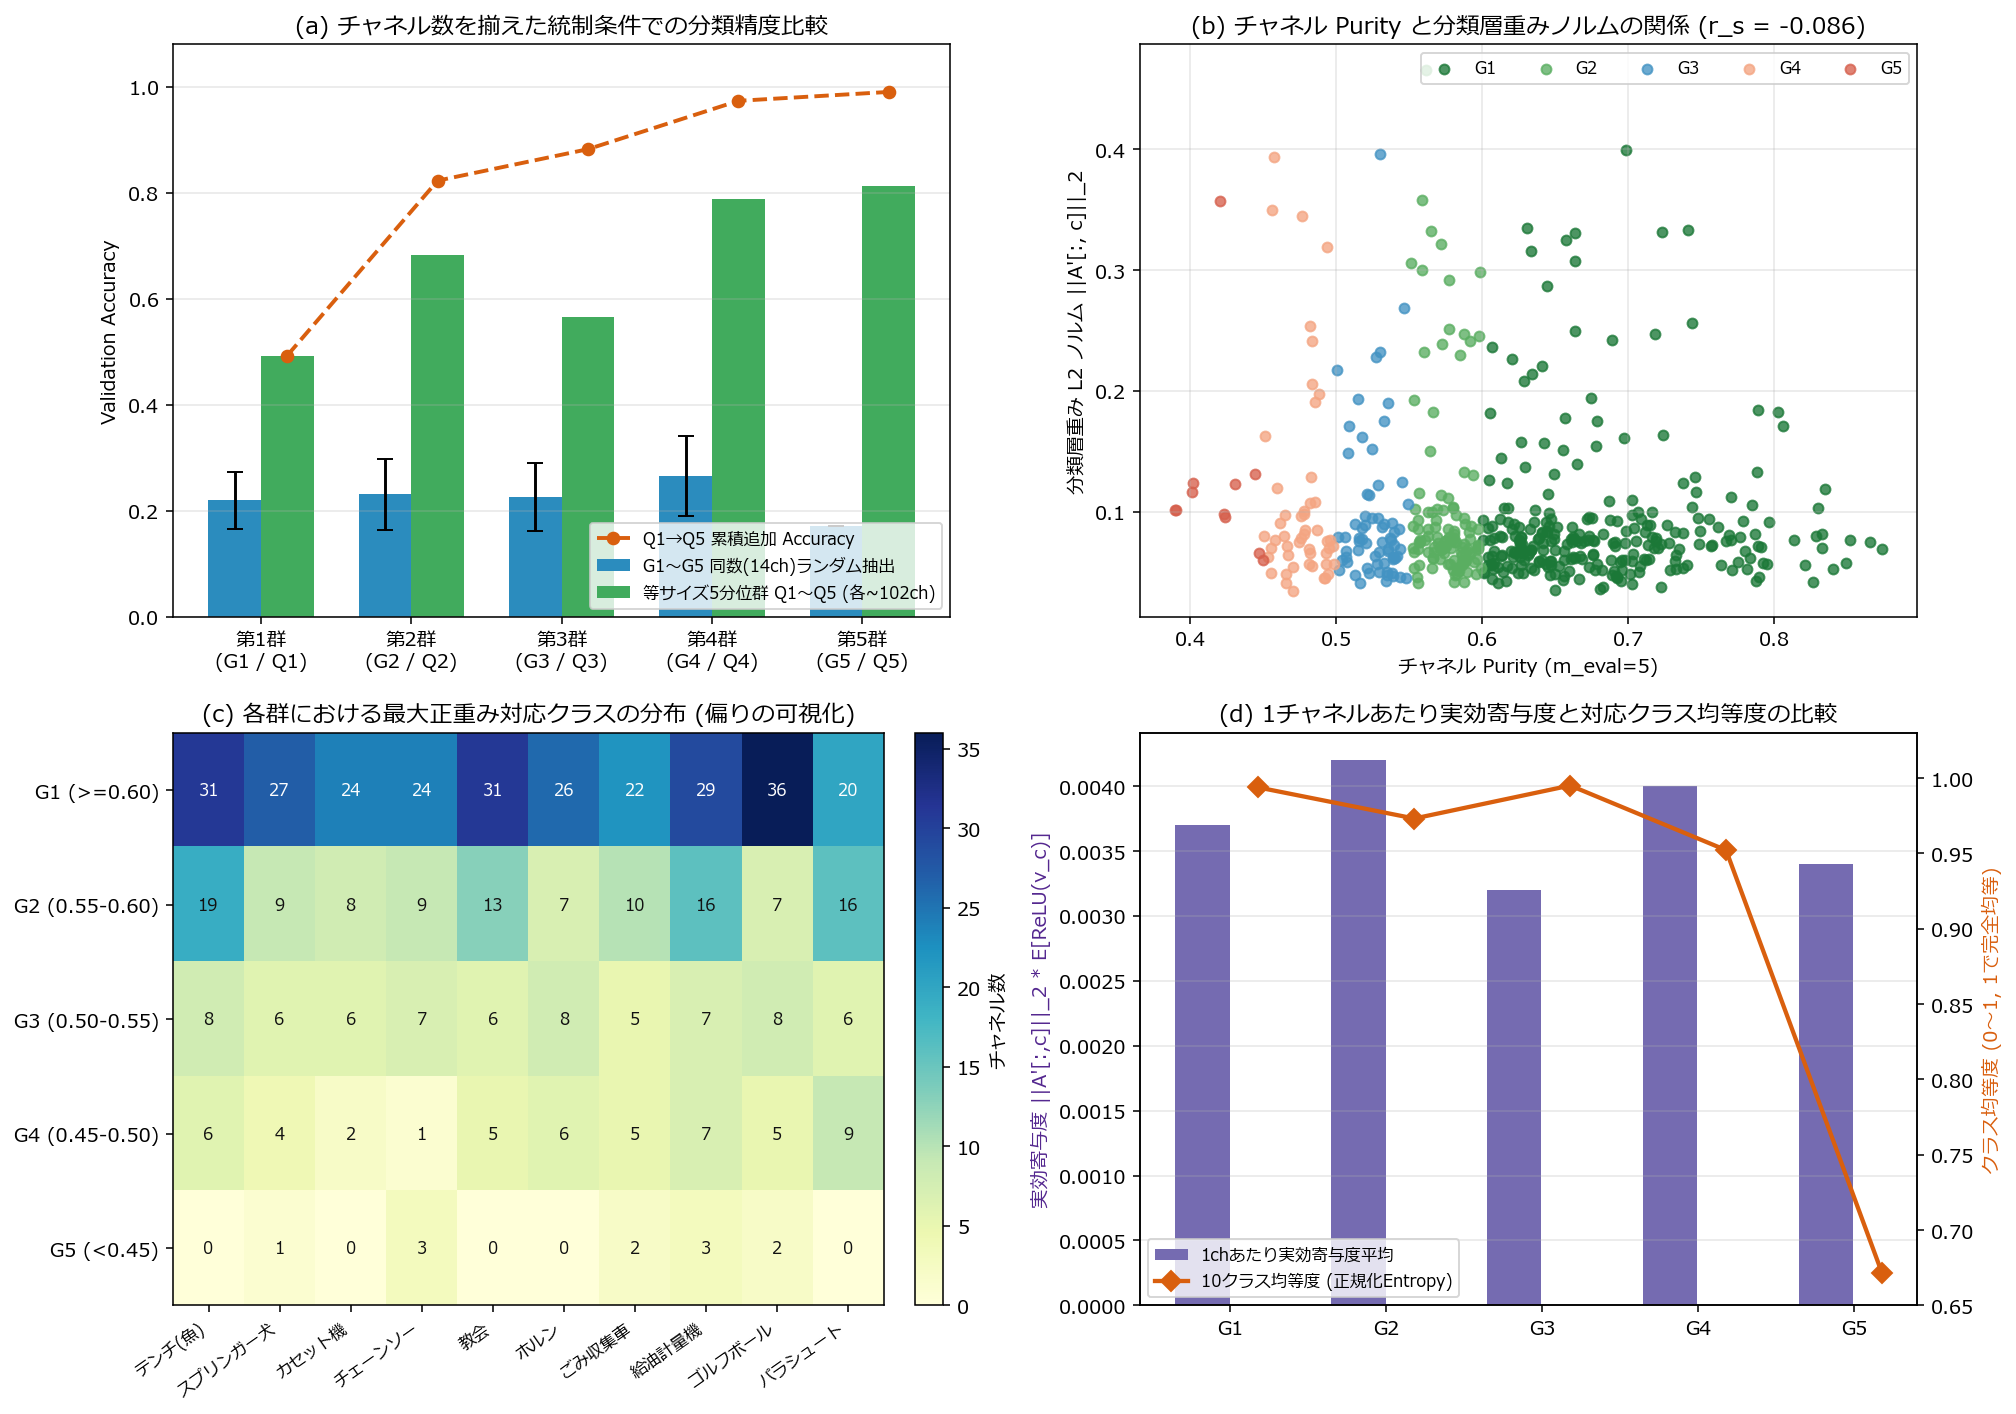

In [5]:
group_analysis_df, quintile_df, class_dist_df = analyze_confounding_factors(
    epic_model,
    purities=pur_after_m5,
    groups=groups_m5,
    z_val=z_val,
    y_val=y_val,
    device=device,
    subsample_k=14,
    num_trials=100,
    seed=42,
)

print("=== [1] 群別の重みノルム・実効寄与度・クラスカバー率・同数チャネル抽出精度 ===")
display(group_analysis_df)

print("=== [2] チャネル数を完全統一（約102ch×5群）した等数5分位群 (Q1〜Q5) での評価 ===")
display(quintile_df)

print("=== [3] 各群における最大重み対応クラスのチャネル数内訳（10クラス分布）===")
display(class_dist_df)

# チャネル単位での Purity と分類層重みノルムの Spearman 相関を算出
a_prime = epic_model.get_modified_fc_weight().detach().cpu()
weight_l2_all = a_prime.norm(dim=0).numpy()
pur_np = pur_after_m5.numpy()
spearman_r = pd.Series(pur_np).corr(pd.Series(weight_l2_all), method="spearman")
print(f"全512チャネルにおける Purity と 分類層重み L2 ノルム ||A'[:, c]||_2 の Spearman 相関 r_s = {spearman_r:.4f}")

# 図4: 交絡要因の4パネル定量解析図
fig, axes = plt.subplots(2, 2, figsize=(14.5, 10.2))

# (a) チャネル数統制実験: 同数抽出 (14ch) & 等サイズ5分位群 (Q1〜Q5)
ax_a = axes[0, 0]
k_col_mean = [c for c in group_analysis_df.columns if "抽出精度_平均" in c][0]
k_col_std = [c for c in group_analysis_df.columns if "抽出精度_標準偏差" in c][0]
x_idx = np.arange(5)
w = 0.35

ax_a.bar(
    x_idx - w / 2,
    group_analysis_df[k_col_mean].values,
    yerr=group_analysis_df[k_col_std].values,
    capsize=4,
    width=w,
    color="#2b8cbe",
    label="G1〜G5 同数(14ch)ランダム抽出",
)
ax_a.bar(
    x_idx + w / 2,
    quintile_df["単独Accuracy"].values,
    width=w,
    color="#41ab5d",
    label="等サイズ5分位群 Q1〜Q5 (各~102ch)",
)
ax_a.plot(
    x_idx + w / 2,
    quintile_df["高Purity側からの累積Accuracy"].values,
    "o--",
    color="#d95f0e",
    linewidth=2,
    label="Q1→Q5 累積追加 Accuracy",
)
ax_a.set_xticks(x_idx)
ax_a.set_xticklabels(["第1群\n(G1 / Q1)", "第2群\n(G2 / Q2)", "第3群\n(G3 / Q3)", "第4群\n(G4 / Q4)", "第5群\n(G5 / Q5)"])
ax_a.set_ylim(0, 1.08)
ax_a.set_ylabel("Validation Accuracy")
ax_a.set_title("(a) チャネル数を揃えた統制条件での分類精度比較")
ax_a.legend(fontsize=8.5, loc="lower right")
ax_a.grid(True, axis="y", alpha=0.3)

# (b) チャネル Purity vs 分類層重み L2 ノルムの散布図
ax_b = axes[0, 1]
for g_name in ["G1", "G2", "G3", "G4", "G5"]:
    m_bool = groups_m5[g_name].numpy()
    ax_b.scatter(
        pur_np[m_bool],
        weight_l2_all[m_bool],
        s=26,
        alpha=0.78,
        color=group_colors[g_name],
        label=g_name,
    )
ax_b.set_xlabel("チャネル Purity (m_eval=5)")
ax_b.set_ylabel("分類層重み L2 ノルム ||A'[:, c]||_2")
ax_b.set_title(f"(b) チャネル Purity と分類層重みノルムの関係 (r_s = {spearman_r:.3f})")
ax_b.legend(fontsize=8.5, ncol=5, loc="upper right")
ax_b.grid(True, alpha=0.3)

# (c) 群×対応クラス (10クラス) のチャネル分布ヒートマップ
ax_c = axes[1, 0]
heat_mat = class_dist_df[IMAGENETTE_CLASSES_JA].values.astype(float)
# 行ごとに構成比(%)も併記しやすいよう生カウントを可視化
im = ax_c.imshow(heat_mat, cmap="YlGnBu", aspect="auto")
ax_c.set_xticks(np.arange(len(IMAGENETTE_CLASSES_JA)))
ax_c.set_xticklabels(IMAGENETTE_CLASSES_JA, rotation=35, ha="right", fontsize=8.5)
ax_c.set_yticks(np.arange(5))
ax_c.set_yticklabels(["G1 (>=0.60)", "G2 (0.55-0.60)", "G3 (0.50-0.55)", "G4 (0.45-0.50)", "G5 (<0.45)"])
for i in range(heat_mat.shape[0]):
    for j in range(heat_mat.shape[1]):
        val_ij = int(heat_mat[i, j])
        txt_col = "white" if val_ij > heat_mat.max() * 0.55 else "#111111"
        ax_c.text(j, i, str(val_ij), ha="center", va="center", color=txt_col, fontsize=8.5)
fig.colorbar(im, ax=ax_c, fraction=0.046, pad=0.04, label="チャネル数")
ax_c.set_title("(c) 各群における最大正重み対応クラスの分布 (偏りの可視化)")

# (d) 群別の実効寄与度平均とクラス均等度 (正規化エントロピー)
ax_d = axes[1, 1]
x_g5 = np.arange(5)
b_imp = ax_d.bar(x_g5 - 0.18, group_analysis_df["実効寄与度平均"].values, width=0.35, color="#756bb1", label="1chあたり実効寄与度平均")
ax_d.set_ylabel("実効寄与度 ||A'[:,c]||_2 * E[ReLU(v_c)]", color="#54278f")
ax_d.set_xticks(x_g5)
ax_d.set_xticklabels(["G1", "G2", "G3", "G4", "G5"])
ax_d.grid(True, axis="y", alpha=0.3)

ax_d2 = ax_d.twinx()
ax_d2.plot(x_g5 + 0.18, group_analysis_df["クラス均等度(Entropy)"].values, "D-", color="#d95f0e", linewidth=2.2, markersize=7, label="10クラス均等度 (正規化Entropy)")
ax_d2.set_ylabel("クラス均等度 (0〜1, 1で完全均等)", color="#d95f0e")
ax_d2.set_ylim(0.65, 1.03)
ax_d.set_title("(d) 1チャネルあたり実効寄与度と対応クラス均等度の比較")

l1, lb1 = ax_d.get_legend_handles_labels()
l2, lb2 = ax_d2.get_legend_handles_labels()
ax_d.legend(l1 + l2, lb1 + lb2, loc="lower left", fontsize=8.5)

plt.tight_layout()
plt.savefig(IMG_DIR / "ex002_confounding_analysis.png", dpi=160, bbox_inches="tight")
plt.show()

## 5. Purity 群（G1・G3・G5）別の視覚的プロトタイプ特徴の比較

最後に，高分離度群 `G1`（ $\mathrm{Purity} \geq 0.60$ ），中分離度群 `G3`（ $0.50 \leq \mathrm{Purity} \lt 0.55$ ），および低分離度群 `G5`（ $\mathrm{Purity} \lt 0.45$ ）からそれぞれ代表的なチャネルを抽出し，訓練データにおける上位3枚のプロトタイプ画像と活性化バウンディングボックス（黄色枠）を定性比較する．

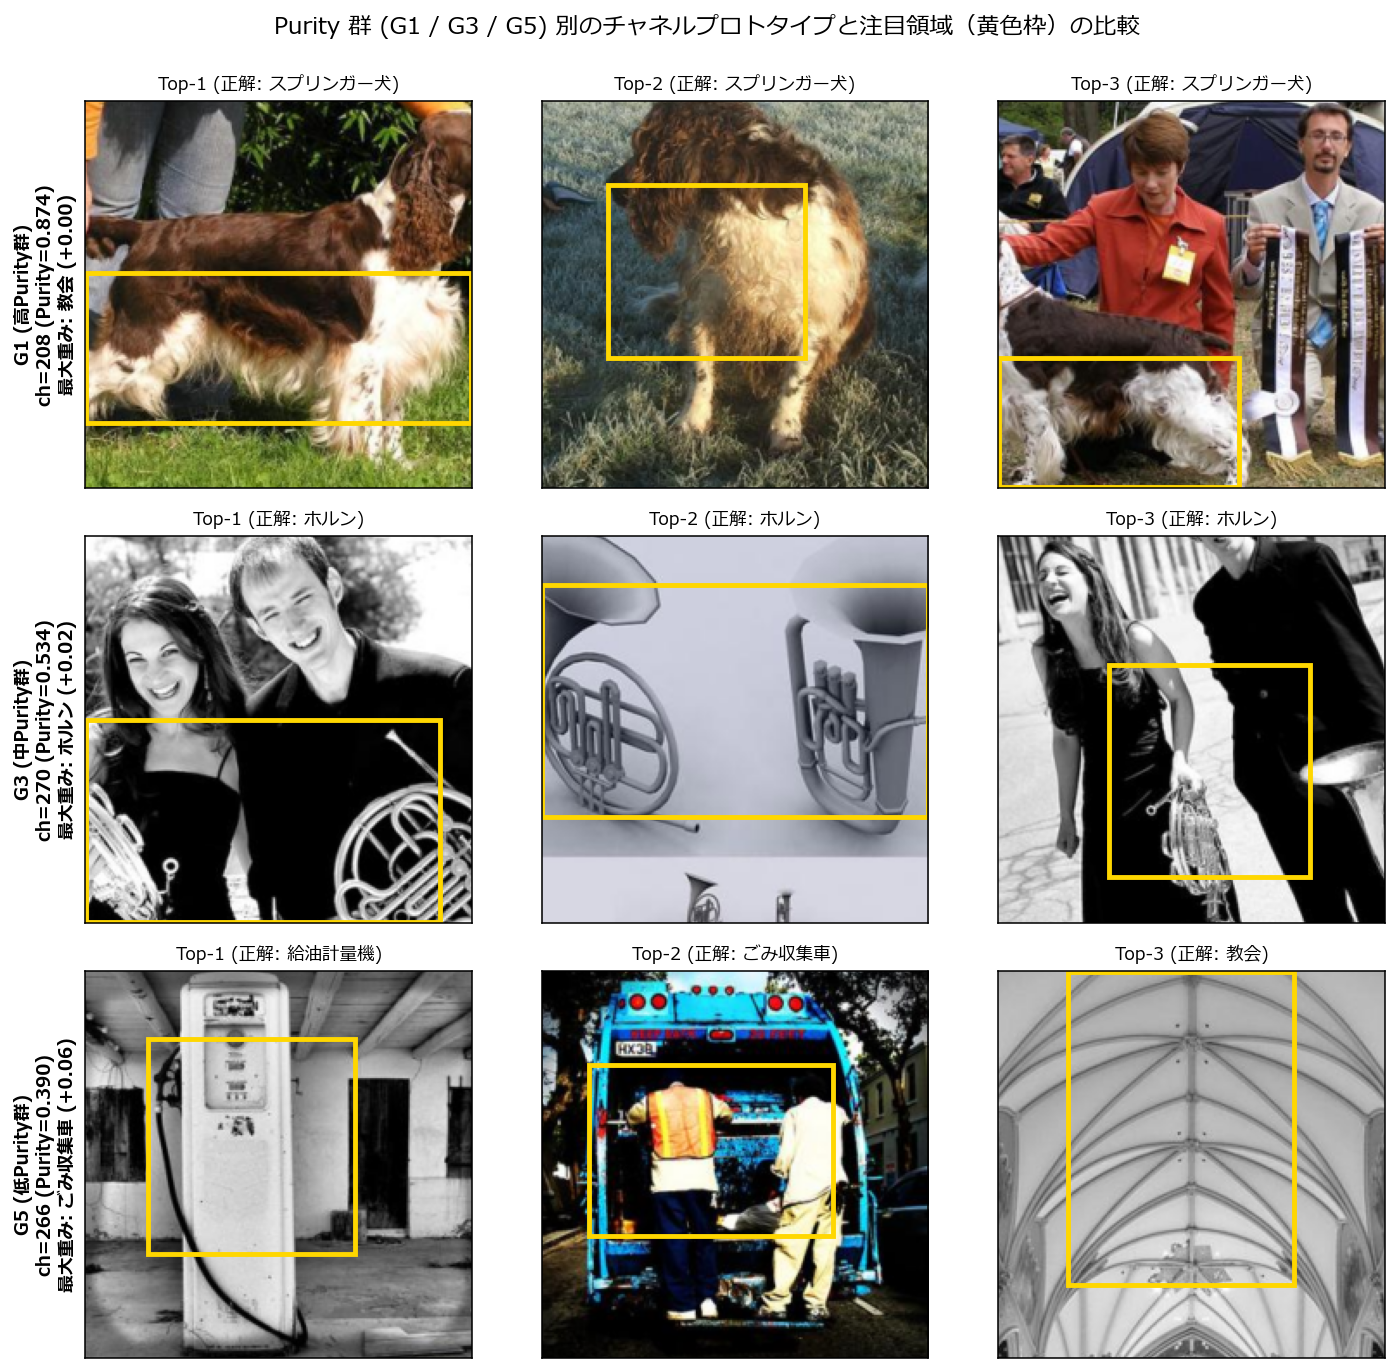

In [6]:
x_train_224 = center_crop_uint8(x_train_256, crop_size=224)

# G1(高Purity群), G3(中Purity群), G5(低Purity群) から正の分類重みを持つ代表チャネルを選出
a_prime_cpu = epic_model.get_modified_fc_weight().detach().cpu()
max_pos_w = a_prime_cpu.max(dim=0).values
clean_cls_set = {0, 1, 2, 4, 5, 6, 7, 8}  # 物体・動物クラスを中心に視覚比較

def _is_clean_top3(ch_idx: int) -> bool:
    return all(int(y_train[int(top_idx_m5[r, ch_idx].item())].item()) in clean_cls_set for r in range(3))

clean_ch_mask = torch.tensor([_is_clean_top3(c) for c in range(512)], dtype=torch.bool)

g1_cand = torch.where(groups_m5["G1"] & clean_ch_mask & (max_pos_w > 0.12))[0]
if len(g1_cand) == 0:
    g1_cand = torch.where(groups_m5["G1"] & clean_ch_mask)[0]
g1_ch = int(g1_cand[pur_after_m5[g1_cand].argmax()].item())

g3_cand = torch.where(groups_m5["G3"] & clean_ch_mask & (max_pos_w > 0.10))[0]
if len(g3_cand) == 0:
    g3_cand = torch.where(groups_m5["G3"] & clean_ch_mask)[0]
g3_ch = int(g3_cand[len(g3_cand) // 2].item())

g5_cand = torch.where(groups_m5["G5"] & clean_ch_mask)[0]
if len(g5_cand) == 0:
    g5_cand = torch.where(groups_m5["G5"])[0]
g5_ch = int(g5_cand[pur_after_m5[g5_cand].argmin()].item())

selected_group_channels = [
    ("G1 (高Purity群)", g1_ch),
    ("G3 (中Purity群)", g3_ch),
    ("G5 (低Purity群)", g5_ch),
]

fig, axes = plt.subplots(3, 3, figsize=(10.5, 9.8))
U_cpu = U_trained.detach().cpu().float()

for row_i, (g_title, ch_id) in enumerate(selected_group_channels):
    dom_cls_idx = int(a_prime_cpu[:, ch_id].argmax().item())
    dom_cls_name = IMAGENETTE_CLASSES_JA[dom_cls_idx]
    dom_w = float(a_prime_cpu[dom_cls_idx, ch_id].item())
    pur_val = float(pur_after_m5[ch_id].item())

    for col_j in range(3):
        img_id = int(top_idx_m5[col_j, ch_id].item())
        img_np = x_train_224[img_id].permute(1, 2, 0).numpy()
        true_cls_name = IMAGENETTE_CLASSES_JA[int(y_train[img_id].item())]

        # 対象チャネルの分離後 7×7 マップを計算して黄色枠を描画
        z_map_orig = z_train[img_id].float()  # (512, 7, 7)
        ch_map_2d = torch.einsum("c,chw->hw", U_cpu[ch_id], z_map_orig)
        x1, y1, x2, y2 = find_activation_bbox(ch_map_2d, img_size=224, rel_threshold=0.50)

        ax = axes[row_i, col_j]
        ax.imshow(img_np)
        rect = patches.Rectangle((x1, y1), max(x2 - x1, 4), max(y2 - y1, 4), linewidth=2.5, edgecolor="#ffd700", facecolor="none")
        ax.add_patch(rect)
        ax.set_xticks([])
        ax.set_yticks([])

        if col_j == 0:
            ax.set_ylabel(
                f"{g_title}\nch={ch_id} (Purity={pur_val:.3f})\n最大重み: {dom_cls_name} ({dom_w:+.2f})",
                fontsize=9.2,
                fontweight="bold",
            )
        ax.set_title(f"Top-{col_j + 1} (正解: {true_cls_name})", fontsize=9.0)

plt.suptitle("Purity 群 (G1 / G3 / G5) 別のチャネルプロトタイプと注目領域（黄色枠）の比較", fontsize=12, y=0.995)
plt.tight_layout()
plt.savefig(IMG_DIR / "ex002_group_prototypes.png", dpi=160, bbox_inches="tight")
plt.show()